In [1]:
# ── Librerías ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import janitor
import sqlalchemy as sa
import os
from pathlib import Path
from dotenv import load_dotenv

%matplotlib inline
# ── Librerías ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import janitor
import sqlalchemy as sa
import os
from pathlib import Path
from dotenv import load_dotenv

%matplotlib inline

# ── Opciones de visualización ─────────────────────────────────────────
# Desactivar notación científica
pd.set_option('display.float_format', '{:.3f}'.format)
np.set_printoptions(suppress=True)

# Ver todas las columnas al imprimir un DataFrame
pd.set_option('display.max_columns', None)

# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ── Variables de entorno ──────────────────────────────────────────────
load_dotenv(RAIZ / '.env')

print('✅ Entorno listo')
print(f'   Raíz del proyecto: {RAIZ}')

✅ Entorno listo
   Raíz del proyecto: c:\Users\Admin\Desktop\Desktop\CarpetaFisica\Data Detective\Mis Casos(Importante)\PROYECTO 5 - FORECASTING RETAIL\02_FORECASTING


In [2]:
cat = pd.read_pickle(ENTRENAMIENTO/'cat_resultado_calidad.pkl')
num = pd.read_pickle(ENTRENAMIENTO/'num_resultado_calidad.pkl')

## EDA CATEGORICAS

### Analisis estadistico

In [3]:
cat.columns.tolist()

['store_id',
 'item_id',
 'dia_ind',
 'year',
 'month',
 'wday',
 'weekday',
 'event_name_1',
 'event_type_1']

In [4]:
incluir = cat.columns.tolist()
del incluir[2]

In [5]:
def frecuencias_cat(df_cat):
    largo = df_cat.astype(str).melt(var_name='variable', value_name='Valor')
    resultado = largo.groupby('variable')['Valor'].value_counts(normalize=True).rename('Frecuencia').reset_index()
    return resultado.sort_values(['variable', 'Frecuencia'], ascending=False).reset_index(drop=True)

In [6]:
pd.set_option('display.max_rows', None)
frecuencias_cat(cat[incluir])

,variable,Valor,Frecuencia
0,year,2014,0.344
1,year,2013,0.341
2,year,2015,0.315
3,weekday,Sunday,0.143
4,weekday,Monday,0.143
5,weekday,Saturday,0.143
6,weekday,Tuesday,0.143
7,weekday,Wednesday,0.143
8,weekday,Thursday,0.143
9,weekday,Friday,0.143


In [7]:
def graficos_eda_categoricos(cat):
    # ── Calculamos el número de filas que necesitamos ─────────────────
    from math import ceil
    filas = ceil(cat.shape[1] / 2)

    # ── Definimos el gráfico ──────────────────────────────────────────
    f, ax = plt.subplots(nrows=filas, ncols=2, figsize=(16, filas * 6))

    # ── Aplanamos para iterar por el gráfico como 1 dimensión ─────────
    ax = ax.flat

    # ── Bucle que va añadiendo gráficos ───────────────────────────────
    for cada, variable in enumerate(cat):
        cat[variable].value_counts().plot.barh(ax=ax[cada])
        ax[cada].set_title(variable, fontsize=12, fontweight="bold")
        ax[cada].tick_params(labelsize=12)

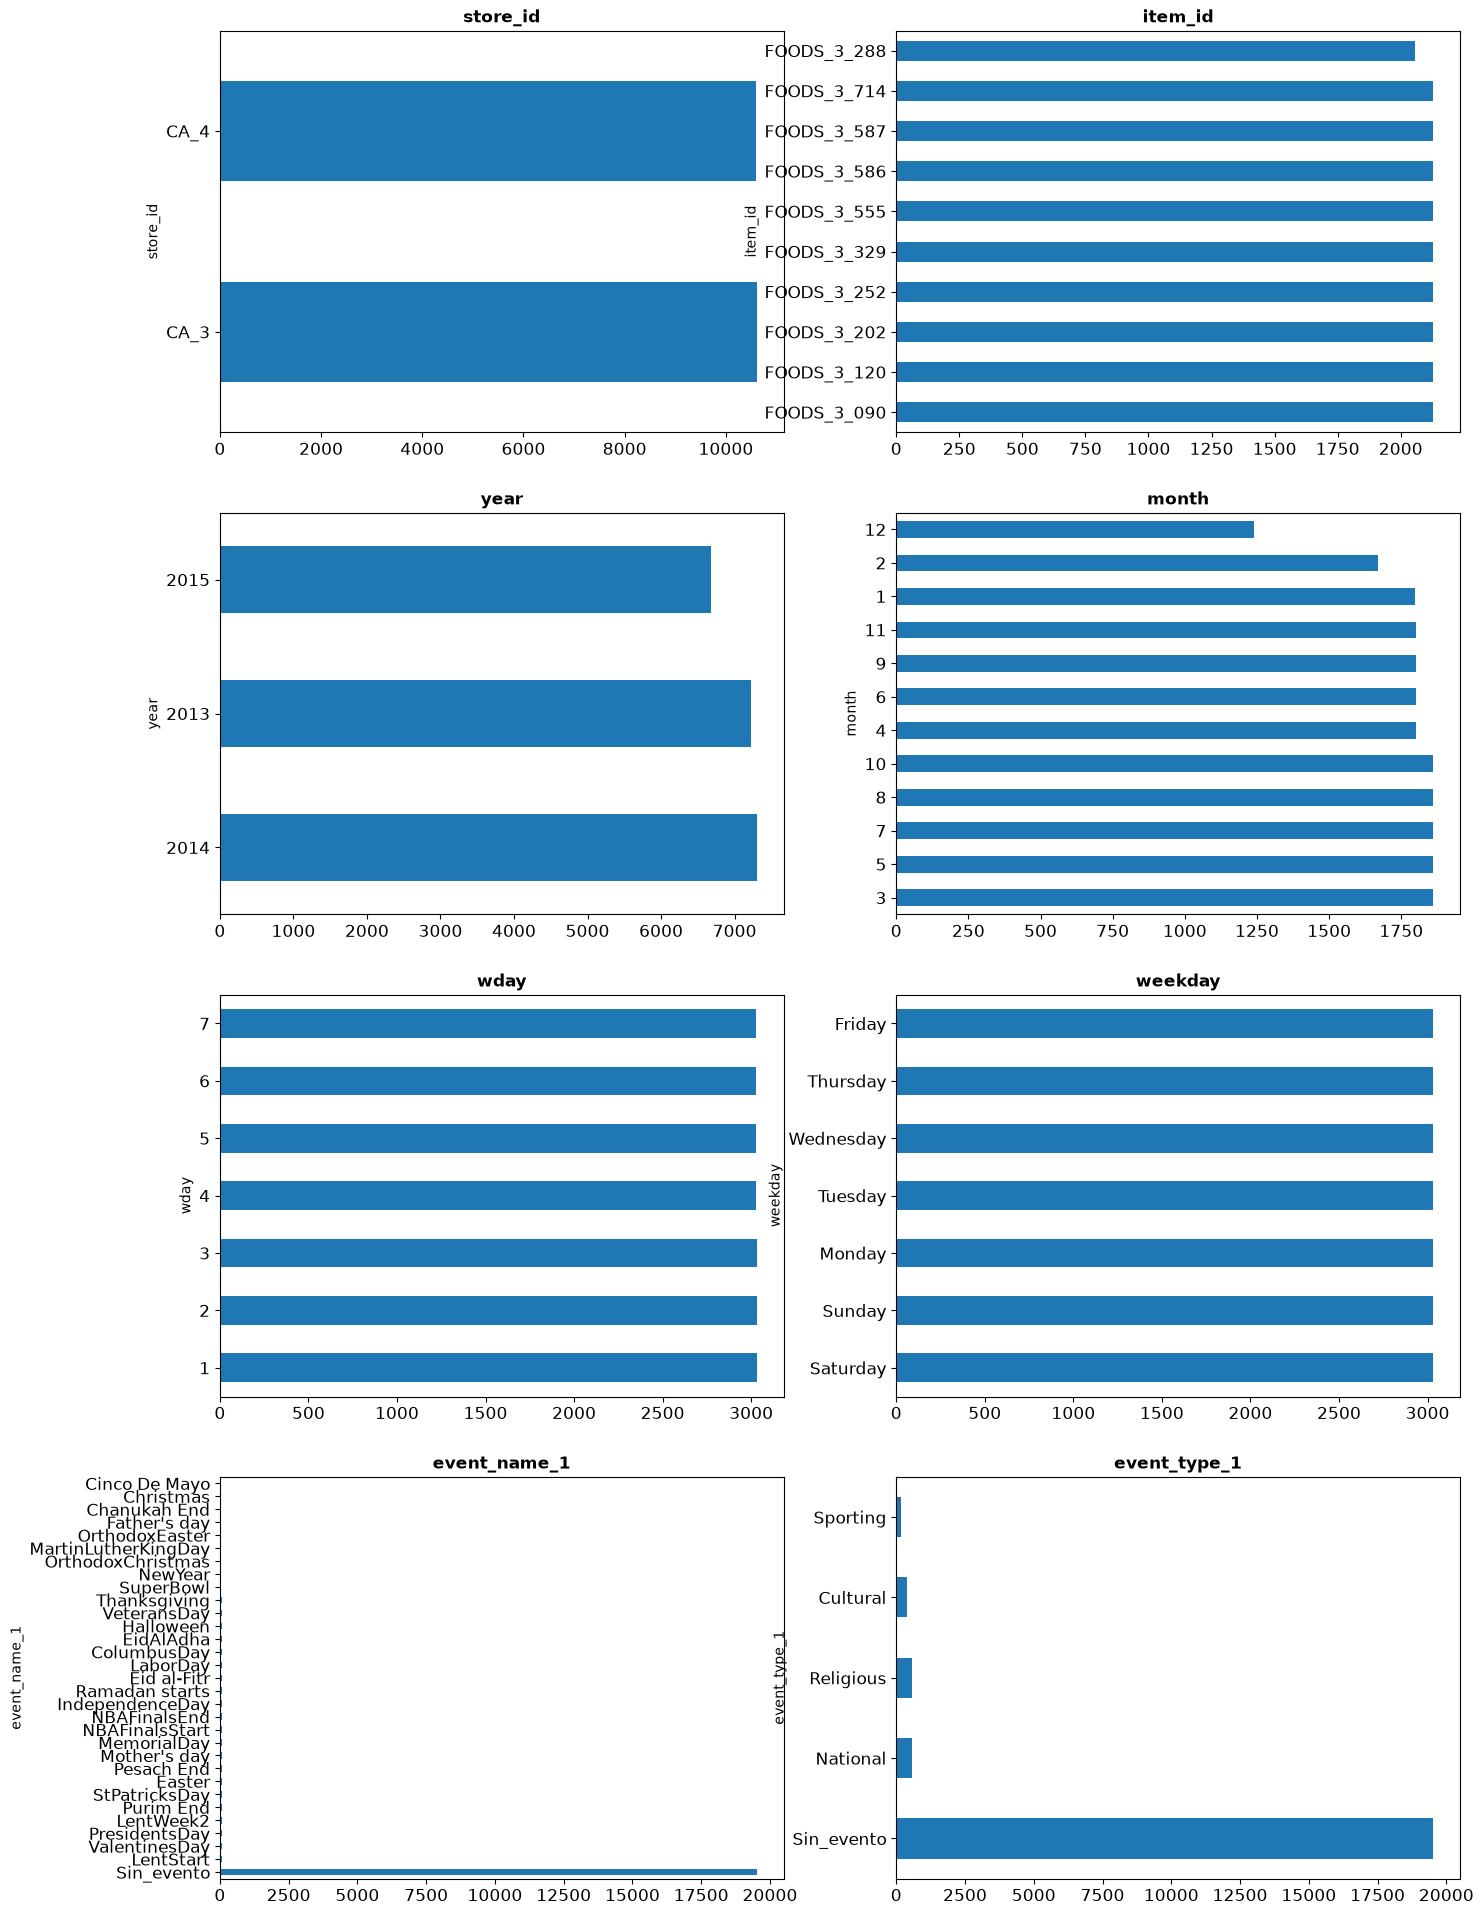

In [8]:
graficos_eda_categoricos(cat[incluir])

## EDA NUMERICAS

### ANALISIS GRAFICO>

In [9]:
df = pd.concat([cat,num],axis=1)
df.head()

,store_id,item_id,dia_ind,year,month,wday,weekday,event_name_1,event_type_1,wm_yr_wk,ventas,sell_price
date,,,,,,,,,,,,
2013-01-01,CA_3,FOODS_3_090,d_704,2013,1,4,Tuesday,NewYear,National,11249,0,1.250
2013-01-01,CA_3,FOODS_3_120,d_704,2013,1,4,Tuesday,NewYear,National,11249,0,4.980
2013-01-01,CA_3,FOODS_3_202,d_704,2013,1,4,Tuesday,NewYear,National,11249,20,4.280
2013-01-01,CA_3,FOODS_3_252,d_704,2013,1,4,Tuesday,NewYear,National,11249,34,1.480
2013-01-01,CA_3,FOODS_3_329,d_704,2013,1,4,Tuesday,NewYear,National,11249,39,2.980


#### Tendencia global de ventas

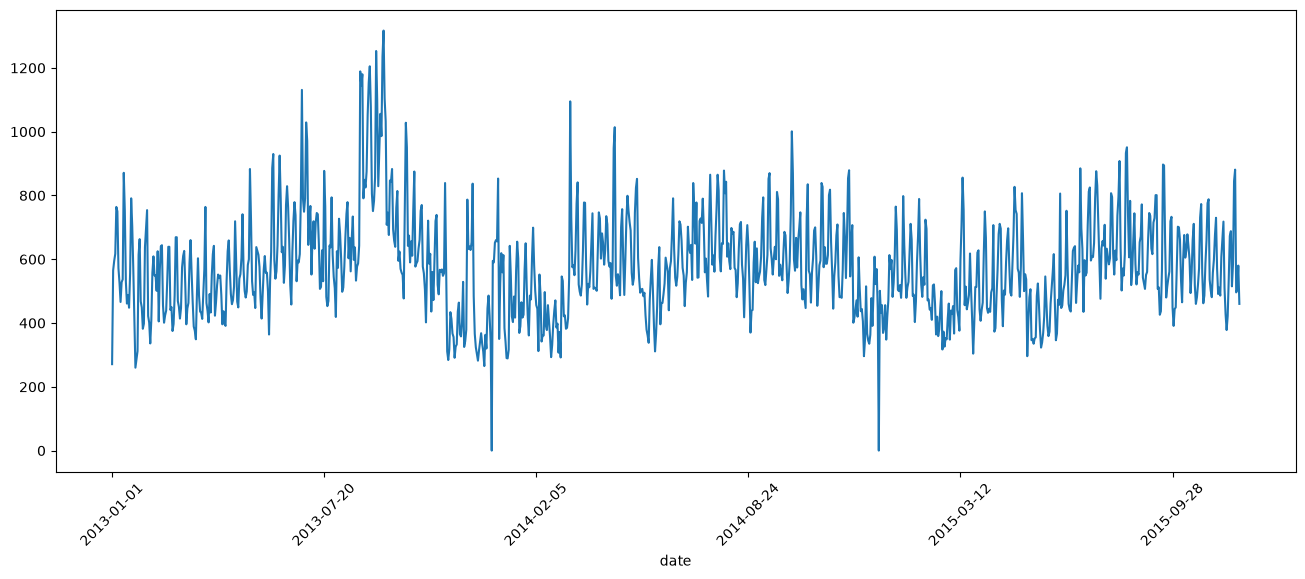

In [10]:
df.groupby('date')['ventas'].sum().plot(figsize =(16,6),rot=45);

### Tendencia de las ventas por producto

In [20]:
df.loc[(df['item_id'] == 'FOODS_3_329') & (df['ventas'] == 0)].head(5)

,store_id,item_id,dia_ind,year,month,wday,weekday,event_name_1,event_type_1,wm_yr_wk,ventas,sell_price
date,,,,,,,,,,,,
2013-01-01,CA_4,FOODS_3_329,d_704,2013,1,4,Tuesday,NewYear,National,11249,0,2.980
2013-03-04,CA_4,FOODS_3_329,d_766,2013,3,3,Monday,Sin_evento,Sin_evento,11306,0,2.980
2013-03-05,CA_3,FOODS_3_329,d_767,2013,3,4,Tuesday,Sin_evento,Sin_evento,11306,0,2.980
2013-03-05,CA_4,FOODS_3_329,d_767,2013,3,4,Tuesday,Sin_evento,Sin_evento,11306,0,2.980
2013-03-06,CA_3,FOODS_3_329,d_768,2013,3,5,Wednesday,Sin_evento,Sin_evento,11306,0,2.980


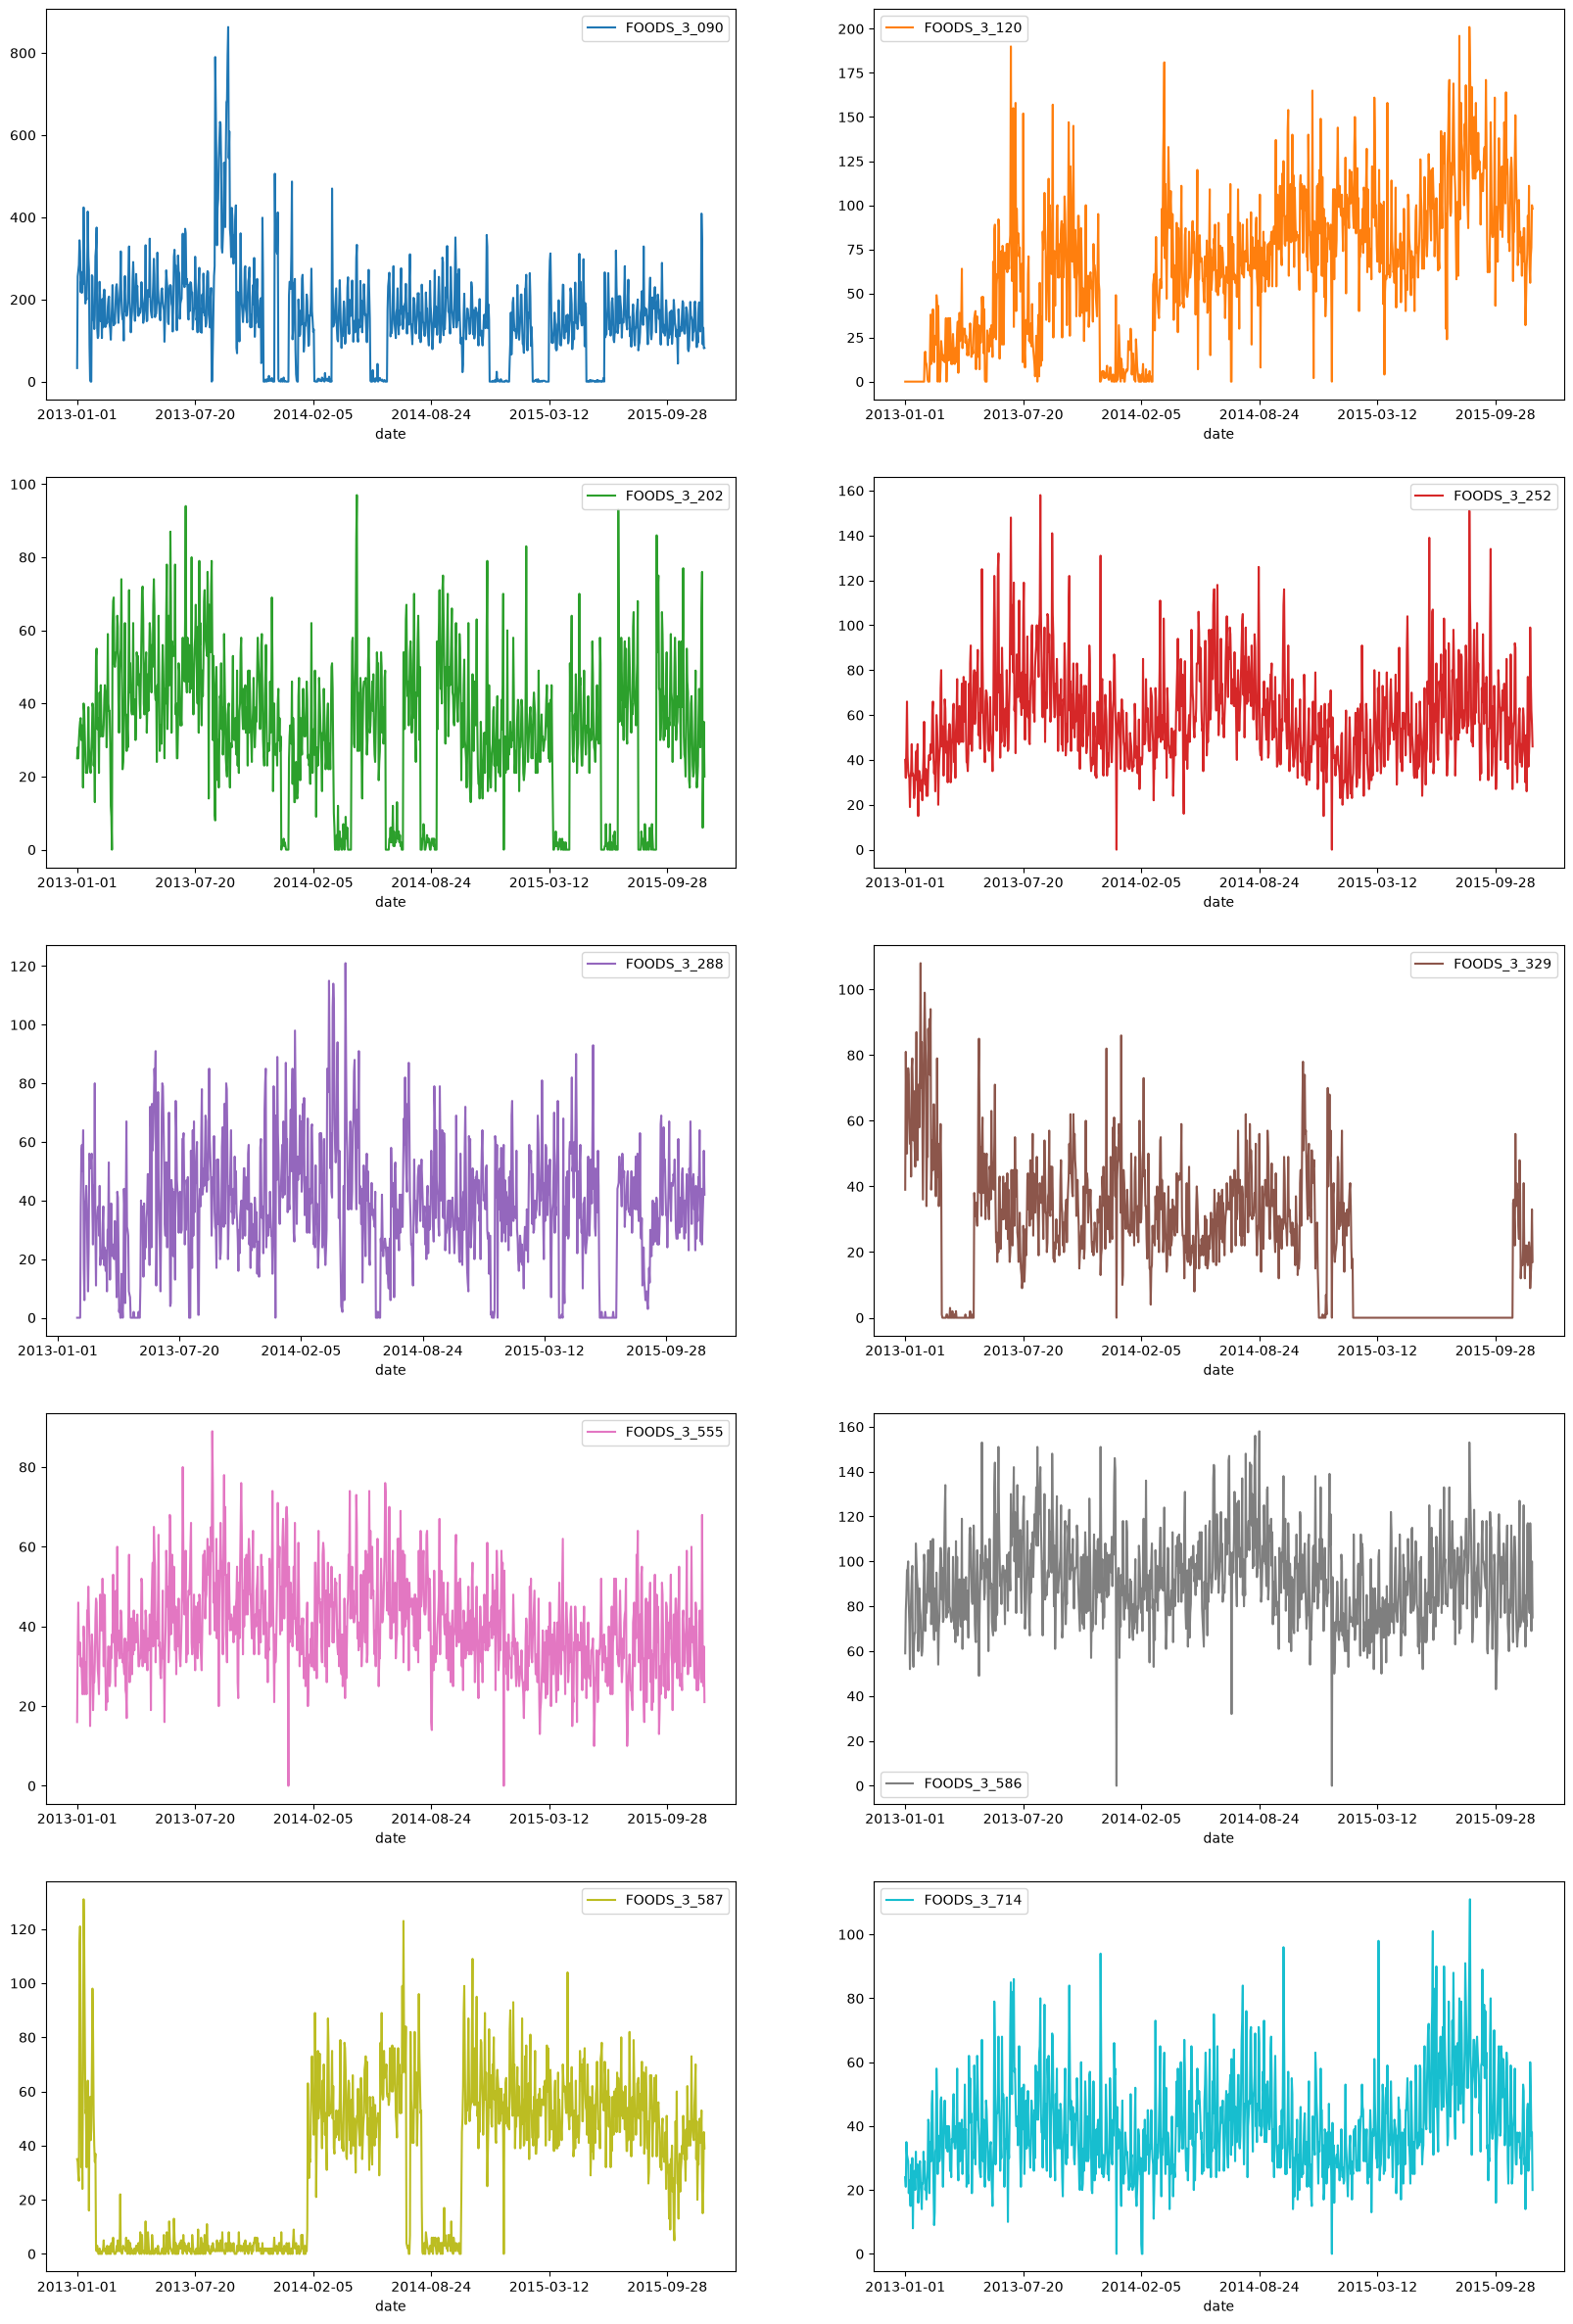

In [ ]:
(df.pivot_table(index='date', columns='item_id', values='ventas', aggfunc='sum')
 .plot(subplots=True, layout =(5,2),sharex=False,figsize = (20,30)));

#### Tendencias de las ventas por tienda y producto

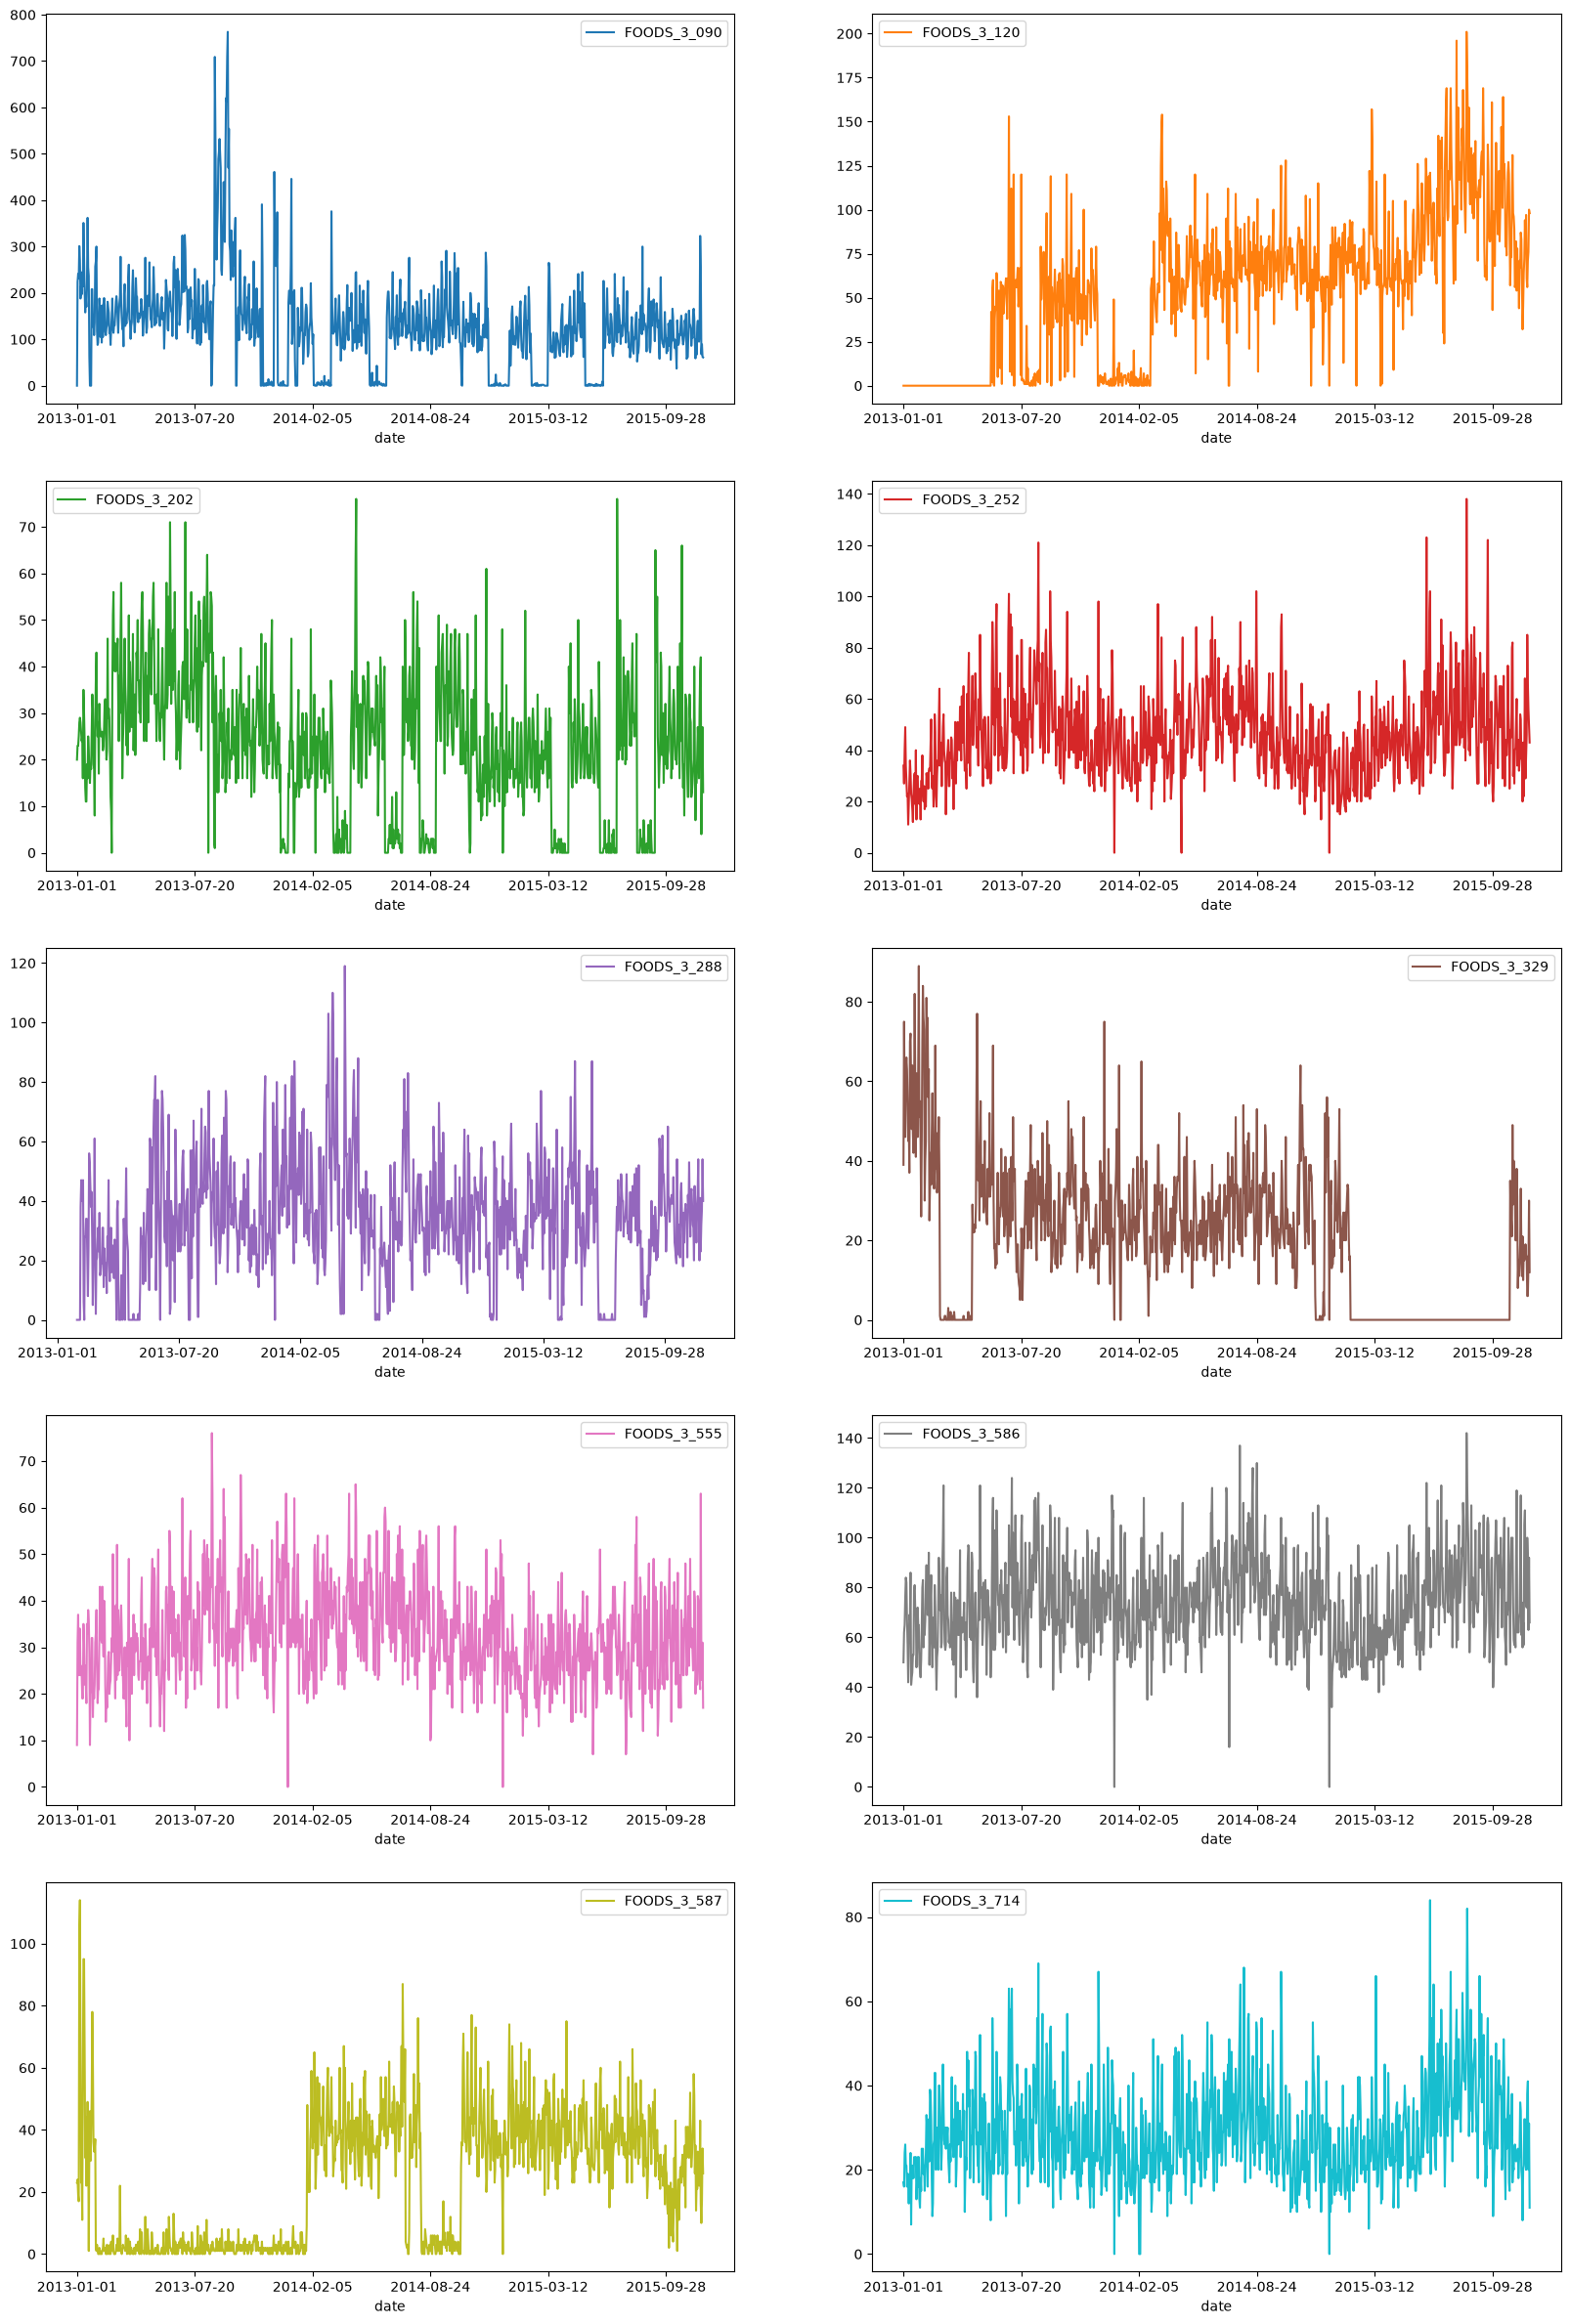

In [21]:
 (df.loc[df.store_id == 'CA_3'].groupby(['date','item_id'])['ventas'].sum()
 .reset_index()
 .pivot_table(index='date', columns='item_id', values='ventas', aggfunc='sum')
 .plot(subplots=True, layout =(5,2),sharex=False,figsize = (20,30)));



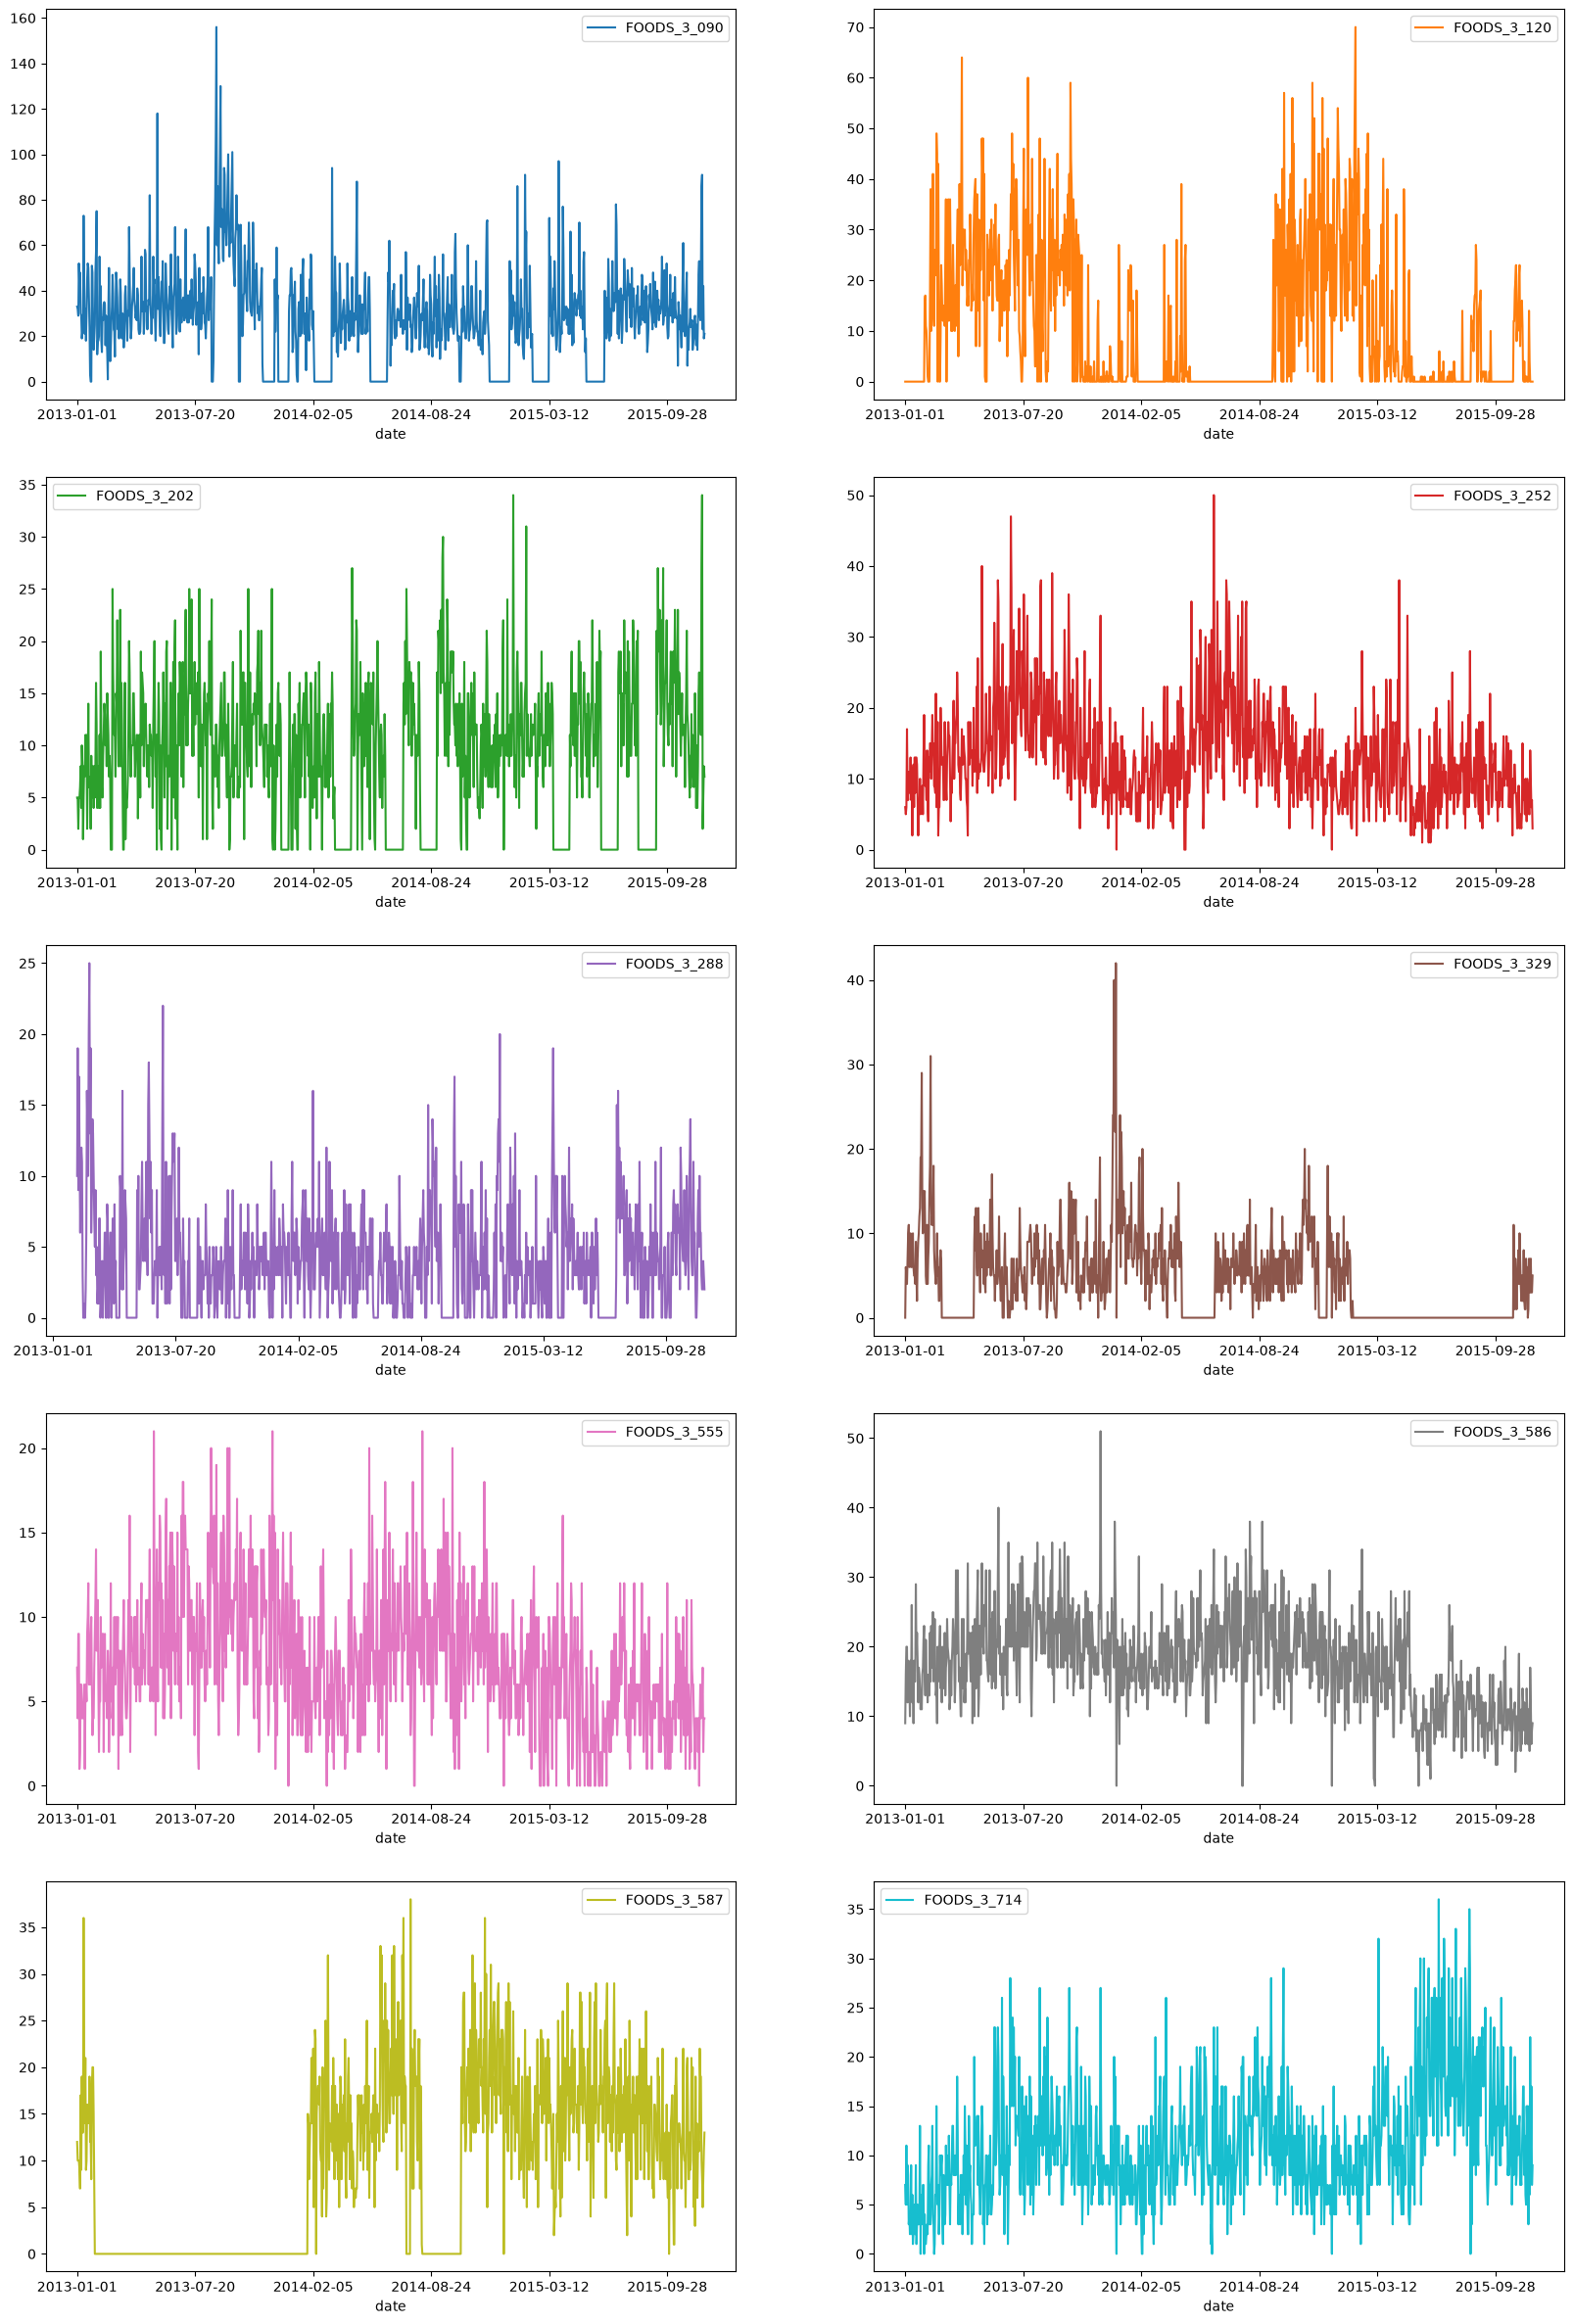

In [22]:
 (df.loc[df.store_id == 'CA_4'].groupby(['date','item_id'])['ventas'].sum()
 .reset_index()
 .pivot_table(index='date', columns='item_id', values='ventas', aggfunc='sum')
 .plot(subplots=True, layout =(5,2),sharex=False,figsize = (20,30)));


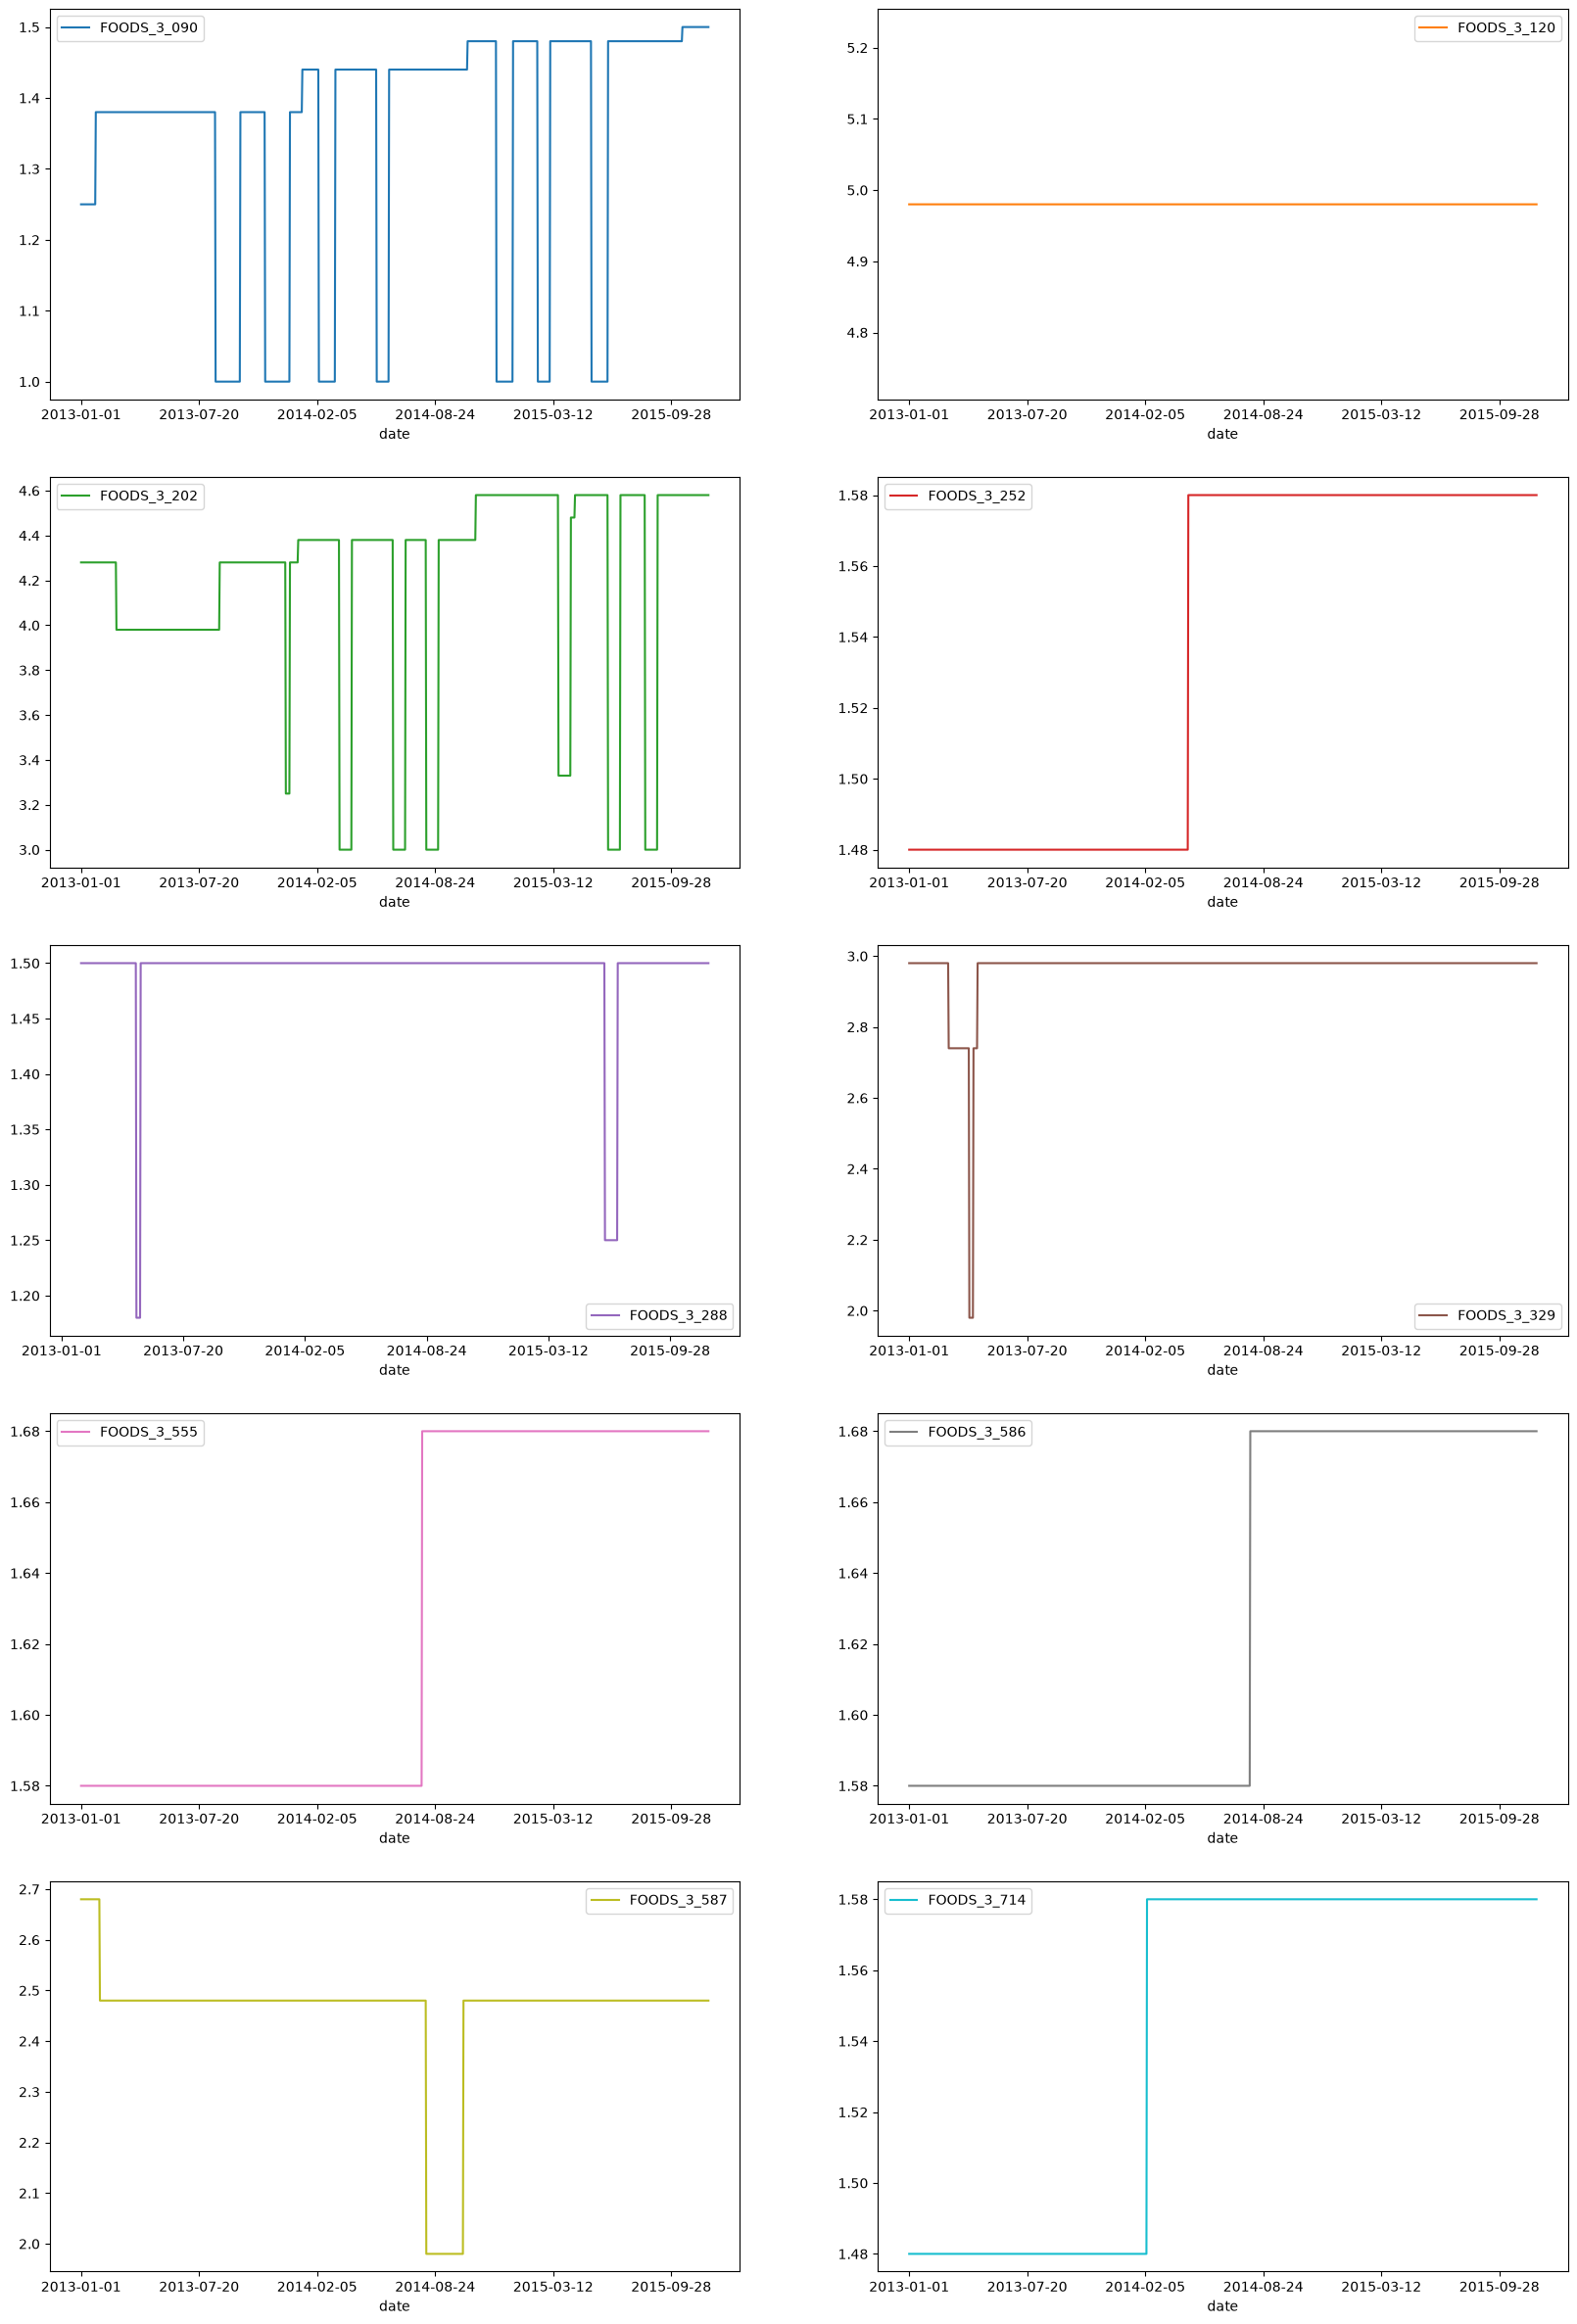

In [24]:
 (df.loc[df.store_id == 'CA_3'].groupby(['date','item_id'])['sell_price'].sum()
 .reset_index()
 .pivot_table(index='date', columns='item_id', values='sell_price', aggfunc='mean')
 .plot(subplots=True, layout =(5,2),sharex=False,figsize = (20,30)));



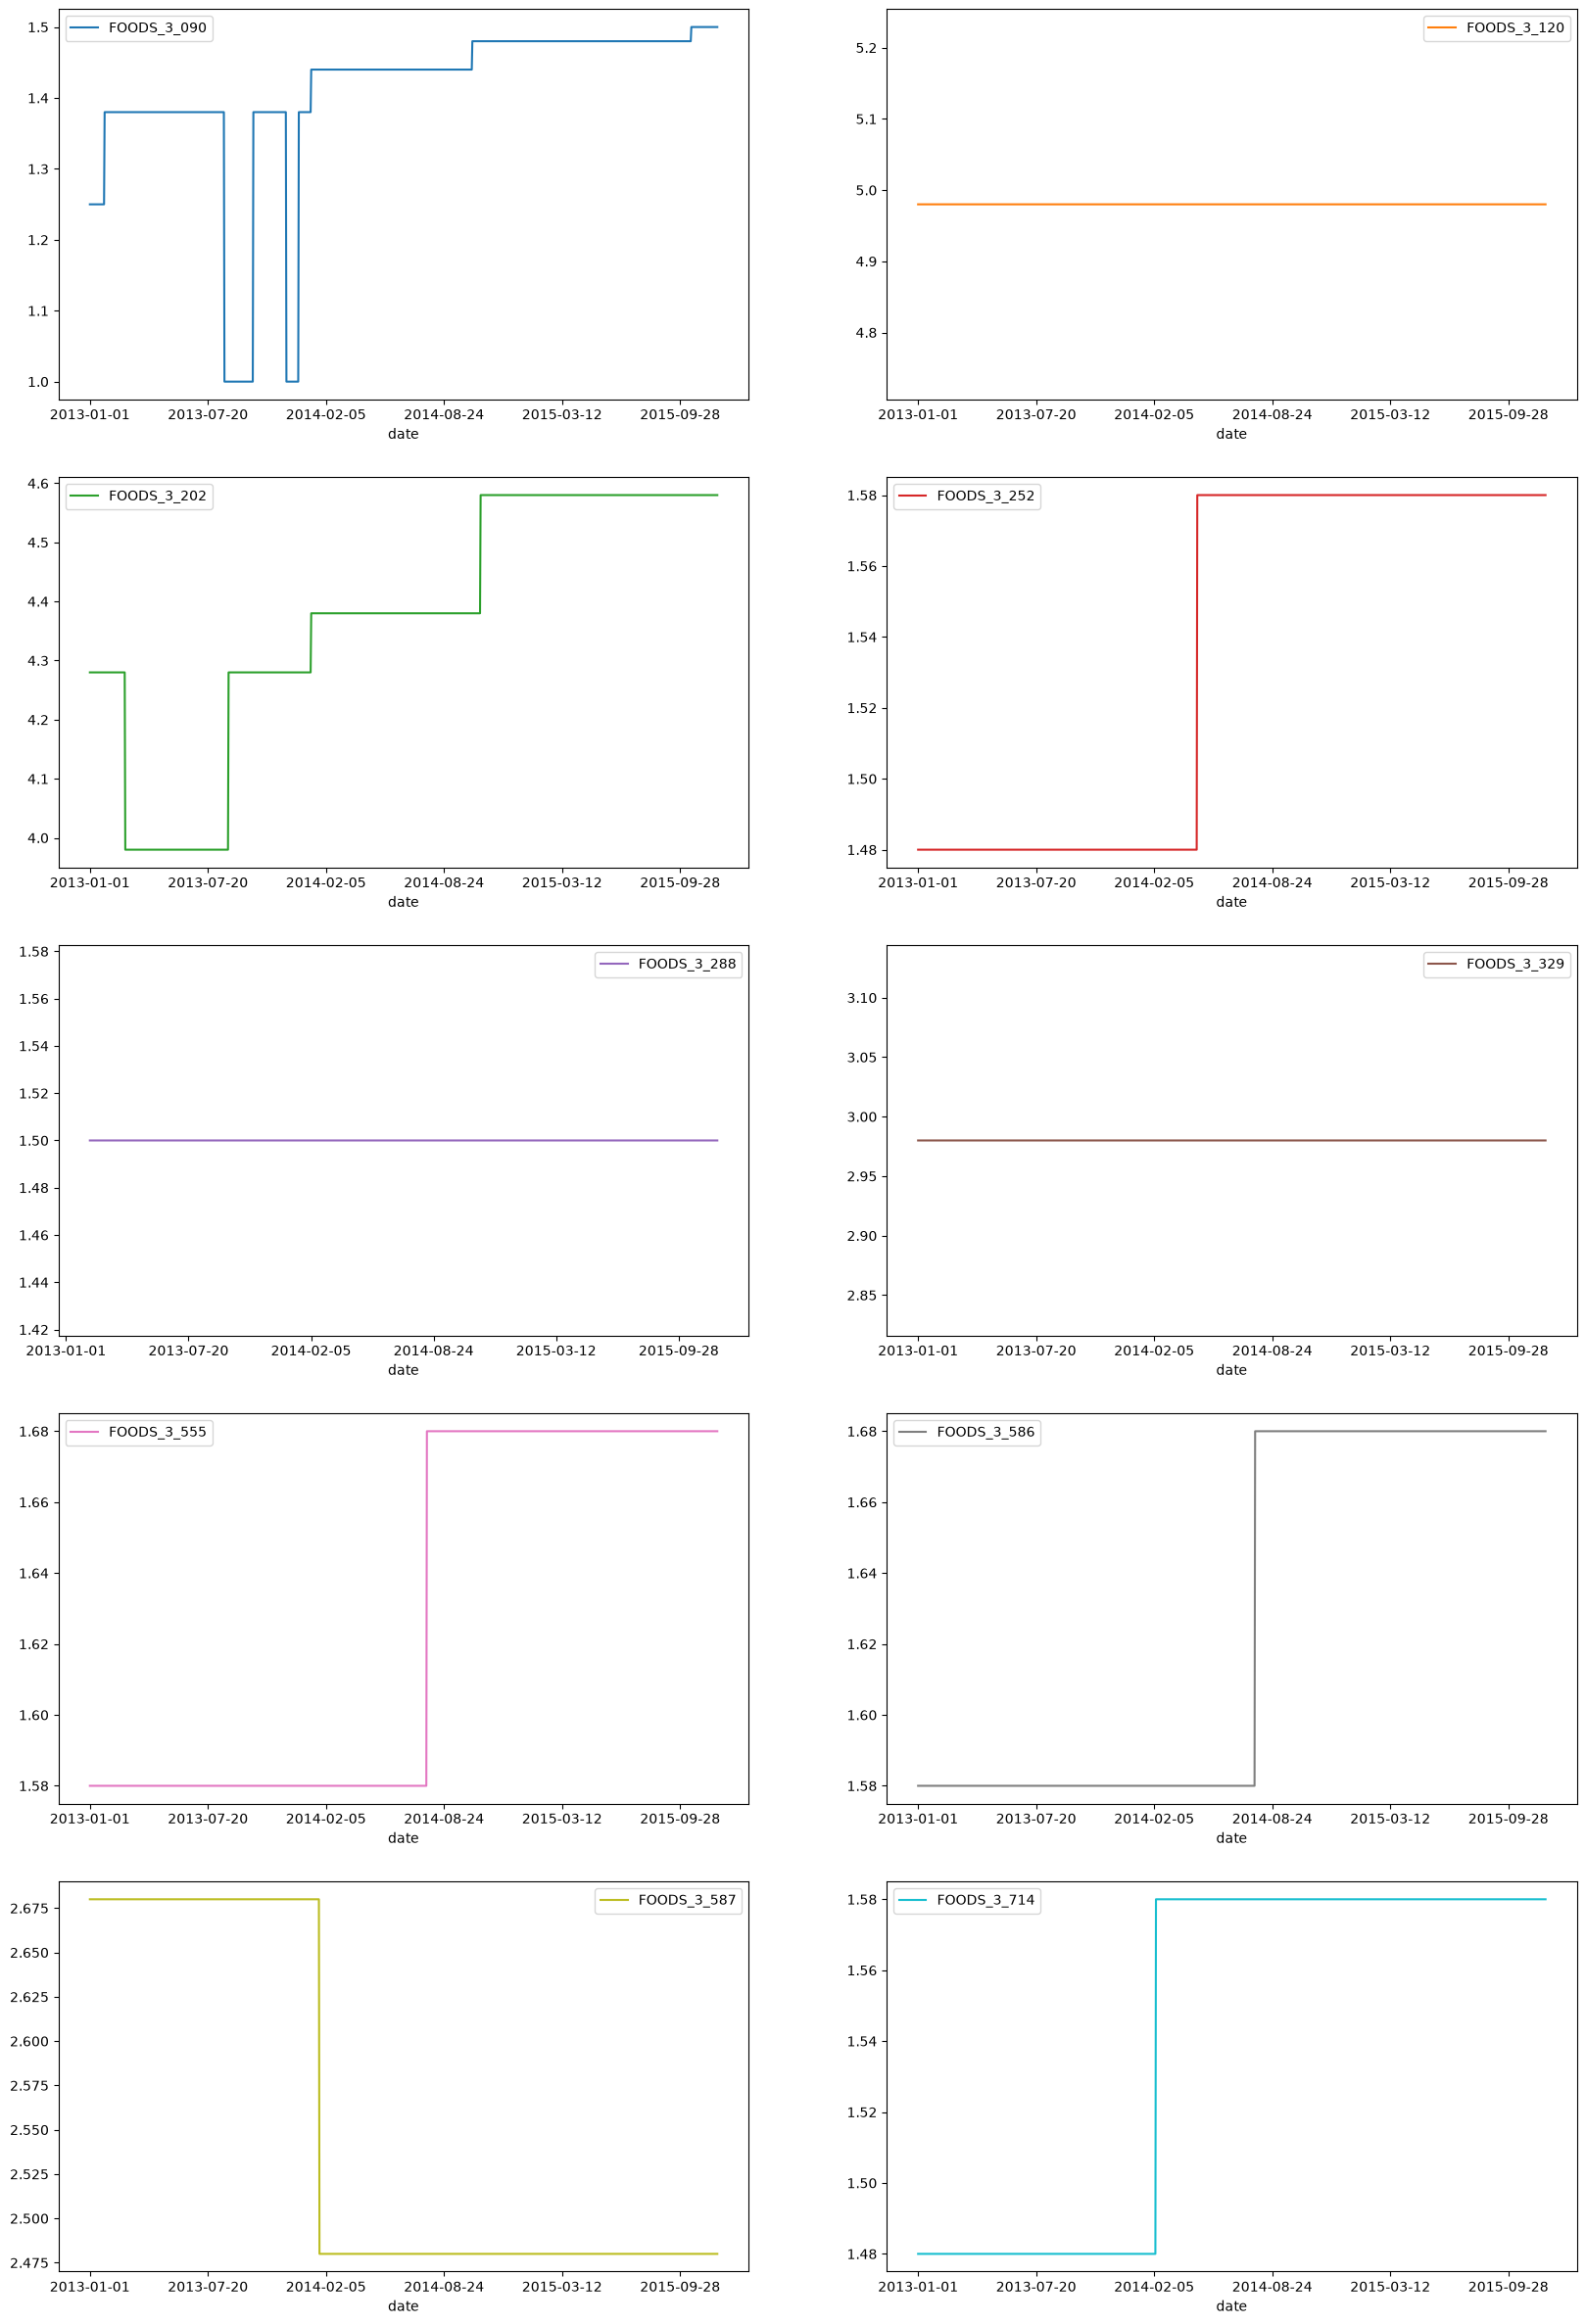

In [28]:
(df.loc[df.store_id == 'CA_4'].groupby(['date','item_id'])['sell_price'].sum()
 .reset_index()
 .pivot_table(index='date', columns='item_id', values='sell_price', aggfunc='mean')
 .plot(subplots=True, layout =(5,2),sharex=False,figsize = (20,30)));

In [34]:
# ── Precios por item-tienda: rango y nº de precios ────────────
df.groupby(['item_id', 'store_id'])['sell_price'].agg(['min', 'max', 'nunique'])

min   max  nunique
item_id     store_id                     
FOODS_3_090 CA_3     1.000 1.500        6
            CA_4     1.000 1.500        6
FOODS_3_120 CA_3     4.980 4.980        1
            CA_4     4.980 4.980        1
FOODS_3_202 CA_3     3.000 4.580        8
            CA_4     3.980 4.580        4
FOODS_3_252 CA_3     1.480 1.580        2
            CA_4     1.480 1.580        2
FOODS_3_288 CA_3     1.180 1.500        3
            CA_4     1.500 1.500        1
FOODS_3_329 CA_3     1.980 2.980        3
            CA_4     2.980 2.980        1
FOODS_3_555 CA_3     1.580 1.680        2
            CA_4     1.580 1.680        2
FOODS_3_586 CA_3     1.580 1.680        2
            CA_4     1.580 1.680        2
FOODS_3_587 CA_3     1.980 2.680        3
            CA_4     2.480 2.680        2
FOODS_3_714 CA_3     1.480 1.580        2
            CA_4     1.480 1.580        2

#### Precio por producto y tienda — conclusiones

- **Precios rígidos**: 13 de las 20 series (item-tienda) tienen 1-2 precios distintos en casi 3 años. Los cambios son escalones permanentes, no promociones (ej. 2014: `_252` 1.48→1.58, `_555`/`_586` 1.58→1.68, `_714` 1.48→1.58; `_587` baja a 2.48).
- **`FOODS_3_120`: precio único constante (4.98) en ambas tiendas** → su serie de ventas refleja demanda pura, sin efecto precio.
- **Promoción habitual** en `_090` y `_202` (6-8 valores, dips a 1.00 y 3.00) → el precio explica parte del volumen.
- **Promos solo en la tienda grande**: `_329` (1.98/2.74 solo CA_3; CA_4 siempre 2.98), `_288` (1.18 en CA_3 vs plano 1.50 en CA_4), `_587` (mín 1.98 vs 2.48) → **el precio no es igual entre tiendas**.
- Implicación fase 04: crear **precio relativo** (precio / modal del item-tienda) y **flag de promoción**; tratar los escalones como cambio de nivel.

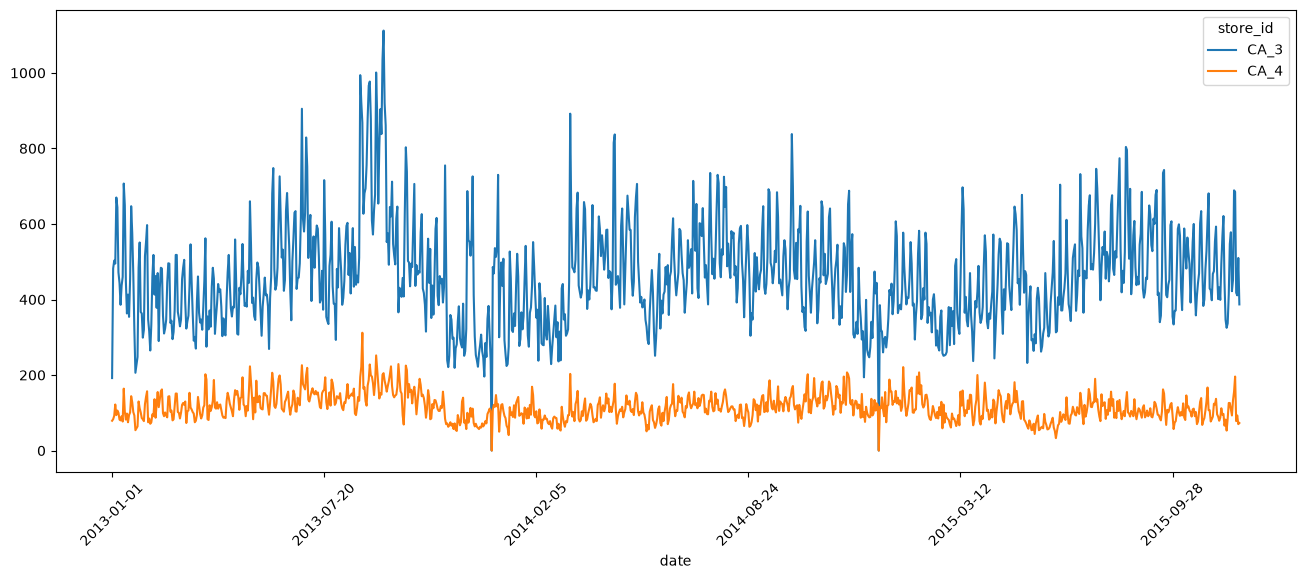

In [29]:
# ── Ventas diarias por tienda (comparativa) ───────────────────
(df.pivot_table(index='date', columns='store_id', values='ventas', aggfunc='sum')
 .plot(figsize=(16, 6), rot=45));

meses: ['1', '10', '11', '12', '2', '3', '4', '5', '6', '7', '8', '9']
dtypes: str | str


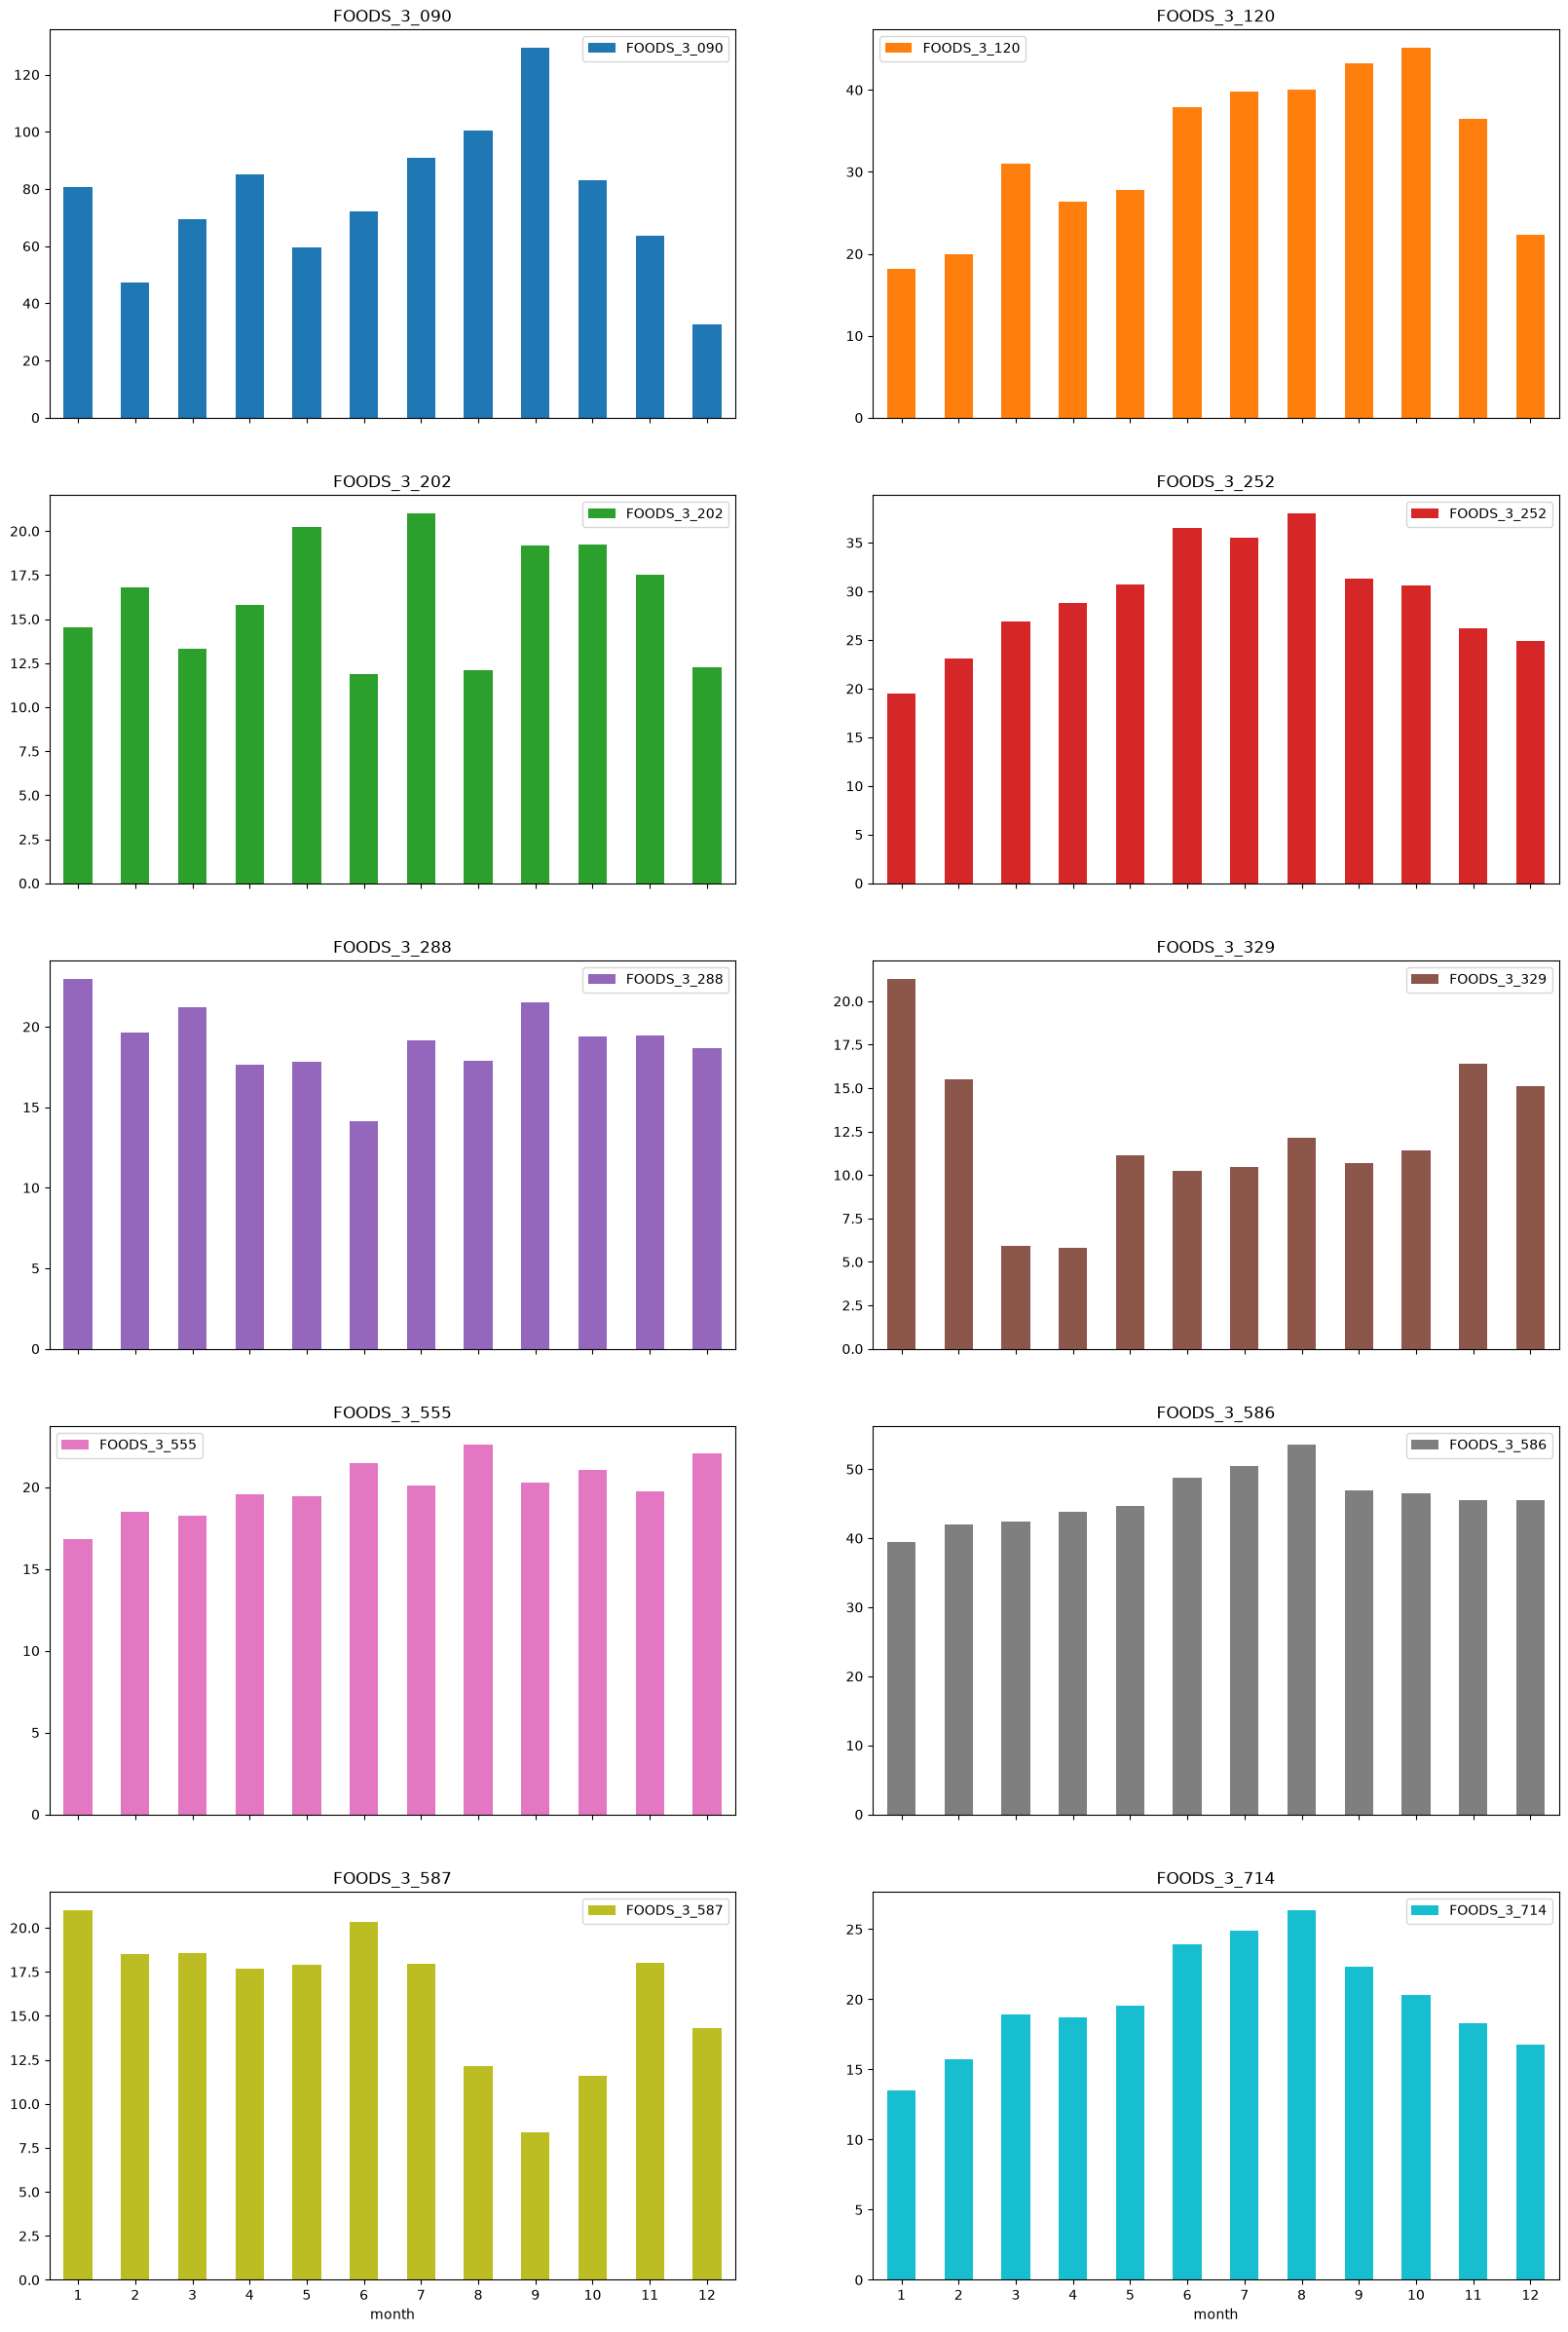

In [30]:
# ── Verificación de columnas para el análisis ─────────────────
print("meses:", sorted(df['month'].unique().tolist()))
print("dtypes:", df['month'].dtype, "|", df['year'].dtype)

# ── Estacionalidad mensual: ventas medias por producto ────────
estacionalidad = df.groupby(['month', 'item_id'])['ventas'].mean().unstack()
estacionalidad.index = estacionalidad.index.astype(int)
estacionalidad = estacionalidad.sort_index()
estacionalidad.plot(subplots=True, layout=(5, 2), kind='bar', figsize=(20, 30), rot=0);

#### Estacionalidad por producto — conclusiones

- **Cada producto tiene su propio calendario** (medias mensuales, ambas tiendas): otoño `_090` (pico octubre) y `_120` (oct-nov); primavera `_202` (mar-abr); verano `_252`, `_586`, `_714` (pico agosto); invierno/enero `_288`, `_329`, `_587`; plana `_555`.
- **No existe un patrón estacional común** → no se puede asumir una única estacionalidad; `month` (o estacionalidad por producto) será variable útil en fase 04.
- ⚠️ El perfil de `_329` está **distorsionado por su bloque de 9 meses a 0** en 2015 (hunde los meses feb-dic).
- ⚠️ `_587` pierde casi todo 2013 en CA_4 (361 días a 0) → su media anual está sesgada a la baja.

In [35]:
# ── % de días sin ventas por item-tienda ──────────────────────
(df['ventas'].eq(0)
 .groupby([df['item_id'], df['store_id']]).mean()
 .mul(100).round(1)
 .unstack())

store_id,CA_3,CA_4
item_id,,
FOODS_3_090,9.400,19.100
FOODS_3_120,18.000,45.500
FOODS_3_202,9.100,20.000
FOODS_3_252,0.300,0.500
FOODS_3_288,7.300,21.600
FOODS_3_329,31.100,38.900
FOODS_3_555,0.200,2.400
FOODS_3_586,0.200,0.600
FOODS_3_587,10.200,41.100


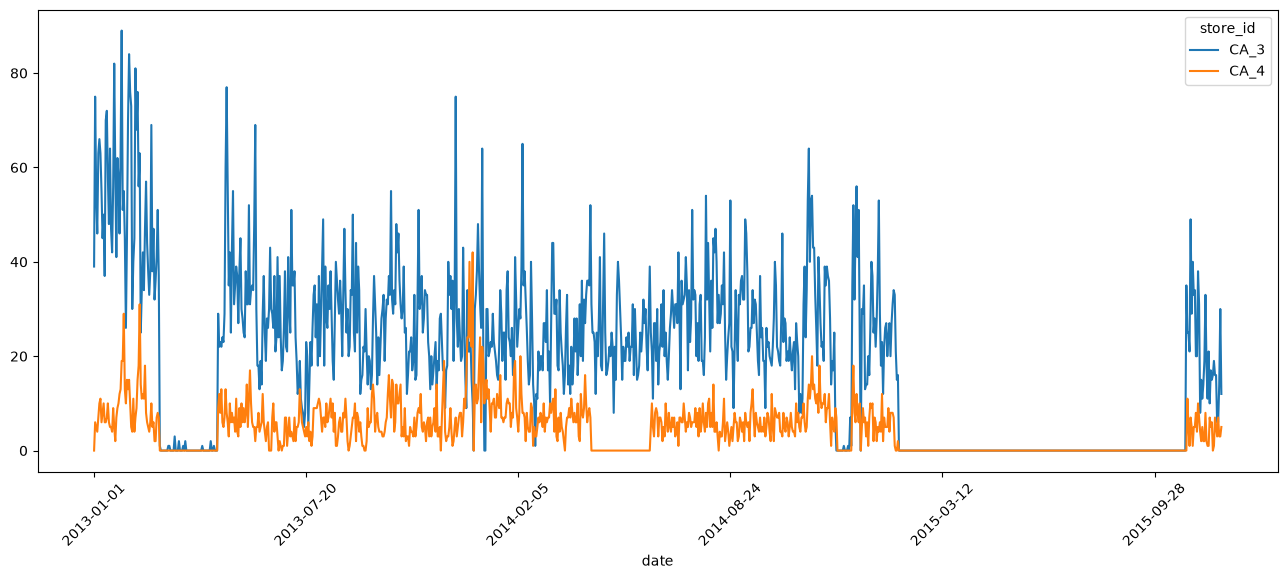

In [36]:
# ── FOODS_3_329: ventas diarias por tienda ────────────────────
(df.loc[df['item_id'] == 'FOODS_3_329']
 .pivot_table(index='date', columns='store_id', values='ventas', aggfunc='sum')
 .plot(figsize=(16, 6), rot=45));

In [37]:
# ── Ventas por item y tienda, con peso de CA_4 ────────────────
totales = df.pivot_table(index='item_id', columns='store_id', values='ventas', aggfunc='sum')
totales['pct_CA_4'] = (100 * totales['CA_4'] / totales.sum(axis=1)).round(1)
totales

store_id,CA_3,CA_4,pct_CA_4
item_id,,,
FOODS_3_090,135292,29811,18.100
FOODS_3_120,58064,11487,16.500
FOODS_3_202,24586,10008,28.900
FOODS_3_252,48860,13938,22.200
FOODS_3_288,34916,4212,10.800
FOODS_3_329,21028,4661,18.100
FOODS_3_555,34645,7807,18.400
FOODS_3_586,78609,18936,19.400
FOODS_3_587,25074,9844,28.200


## Hallazgos para el informe: tiendas, discontinuidad y forecasting multinivel

### 1. Salvedad técnica: el índice
- El índice `date` es de tipo **string** (viaja así desde Calidad de Datos), aunque conceptualmente sea una fecha. `pivot_table`/`groupby` funcionan porque `date` se resuelve como nombre de índice, pero la aritmética de fechas exige `pd.to_datetime`.
- **Acción fase 04**: convertir el índice a datetime (y decidir si queda como índice o columna).

### 2. Diferencias entre tiendas (mismo producto, dos realidades)
- CA_3 = 491.804 uds (**80%**) vs CA_4 = 122.647 uds (20%). Reparto por producto heterogéneo: CA_4 pesa entre 10.8% (`_288`) y 28.9% (`_202`).
- El mismo `item_id` tiene patrón distinto por tienda: `_329` vende 19.8 uds/día en CA_3 vs 4.4 en CA_4; su bloque inicial de ceros (55 días) es solo de CA_4 y sus promos solo existen en CA_3; `_587` tiene 361 días seguidos a 0 en CA_4 mientras CA_3 no tiene ningún tramo ≥7 días.
- Esto justifica **modelizar a nivel tienda-producto**: agregar por producto ocultaría roturas y comportamientos distintos.

### 3. Dos tipos de "0" en ventas (clave para las variables exógenas)
- **0 por falta de demanda**: ceros dispersos en series maduras (252, 555, 586, 714: <1% de días) → venta perdida normal.
- **0 por indisponibilidad/descontinuación**: bloques largos (`_120`-CA_4 140d, `_587`-CA_4 361d, `_329` ambas 271/272d, `_090`-CA_4 34d en Navidad 2014) → no es demanda 0 real.
- El dataset **no trae la causa del 0** → en fase 04 habrá que aproximarla con variables exógenas/proxy (precio relativo, flag de promo, racha de ceros) y decidir el tratamiento (truncar series muertas, imputar, o dejar como 0). Para un target INTERMITENTE mirar Croston/TSB o modelos globales.

### 4. Forecasting jerárquico y multinivel: por qué el nivel importa
- **Uso financiero** (API de facturación futura) → interesa el **total agregado**; **uso logístico** (reparto a cada tienda) → interesa el nivel **tienda-producto**. Un mismo proyecto puede necesitar ambos.
- **Reconciliación**: modelos independientes por nivel dan totales incoherentes (Σ partes ≠ total). Ej.: modelo global predice 1.000 y los modelos de tienda 500 + 600 = 1.100 → financiero y planificación no lo entienden. Soluciones típicas: bottom-up, top-down, middle-out o reconciliación jerárquica (MinT).
- **Decisión de nivel**: total / tienda / producto / tienda-producto / familia / categoría. Aquí: 10 productos × 2 tiendas = **20 series** (26.689 registros). En un retailer real (200 tiendas × 1.000 productos) serían **200.000 series** → modelización masiva (escalado, automatización).
- No es lo mismo `leche` que `carne` dentro de FOODS: agregar por categoría esconde dinámicas, sustitutivos y microeconomía propias.

### 5. Resumen para siguientes fases
- EDA confirma: sin huecos de calendario, precios sin ceros, estacionalidad heterogénea por producto, diferencias de patrón por tienda y bloques de ceros que no son demanda real.
- Insumos directos para fase 04 (transformación): datetime, precio relativo/promo, tratamiento del 0, escalado por nivel, y decisión de truncado o reconciliación.

In [38]:
# ── Verificación: el tablón es cat + num ──────────────────────
original = pd.read_pickle(ENTRENAMIENTO / 'train_resultado_calidad.pkl')

print("cat:", cat.shape, "| num:", num.shape, "| df:", df.shape)
print("columnas = cat + num:", list(cat.columns) + list(num.columns) == list(df.columns))
print("índices alineados:", df.index.equals(cat.index) and df.index.equals(num.index))
print("idéntico al tablón de calidad:", df.sort_index(axis=1).equals(original.sort_index(axis=1)))

cat: (21209, 9) | num: (21209, 3) | df: (21209, 12)
columnas = cat + num: True
índices alineados: True
idéntico al tablón de calidad: True


In [39]:
# ── Guardado del tablón final del EDA ─────────────────────────
df.to_pickle(ENTRENAMIENTO / '03_train_tablon_eda.pkl')
print("guardado:", ENTRENAMIENTO / '03_train_tablon_eda.pkl')

guardado: c:\Users\Admin\Desktop\Desktop\CarpetaFisica\Data Detective\Mis Casos(Importante)\PROYECTO 5 - FORECASTING RETAIL\02_FORECASTING\02_datos\03_Entrenamiento\03_train_tablon_eda.pkl


In [40]:
df.info()

<class 'pandas.DataFrame'>
Index: 21209 entries, 2013-01-01 to 2015-11-30
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   store_id      21209 non-null  str    
 1   item_id       21209 non-null  str    
 2   dia_ind       21209 non-null  str    
 3   year          21209 non-null  str    
 4   month         21209 non-null  str    
 5   wday          21209 non-null  str    
 6   weekday       21209 non-null  str    
 7   event_name_1  21209 non-null  str    
 8   event_type_1  21209 non-null  str    
 9   wm_yr_wk      21209 non-null  int64  
 10  ventas        21209 non-null  int64  
 11  sell_price    21209 non-null  float64
dtypes: float64(1), int64(2), str(9)
memory usage: 2.6+ MB
